# 08 sensitivity analysis

Evaluate weight choices, indicator omission/inclusion and clustering stability without claiming confidence intervals.

Technical evidence for the confirmed Bremen project. Primary comparison: 2024 Ortsteile. No historical change claim; original data preserved.

## Setup and relative paths

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT = Path.cwd()
if not (ROOT / 'src').is_dir():
    ROOT = ROOT.parent
assert (ROOT / 'src' / 'analysis_common.py').exists(), 'Run from root or notebooks directory'
sys.path.insert(0, str(ROOT / 'src'))
from analysis_common import load_analysis, FEATURES
def read(relative):
    return pd.read_csv(ROOT / relative, dtype={'geo_code': str})
def show_figure(name):
    display(Image(filename=str(ROOT / 'results' / 'figures' / name)))


## Data loading and preparation

In [2]:
from sensitivity_analysis import run
frame = load_analysis()

## Calculation and validation

In [3]:
summary = run()
display(summary[~summary.scenario.str.startswith('plausible_random')])
display(read('results/weight_rank_ranges.csv').head(15))
display(read('results/cluster_stability_summary.csv'))

,scenario,method,spearman_vs_baseline,mean_absolute_rank_change,max_absolute_rank_change,top10_overlap,n
0,equal,composite,1.000000,0.000000,0.0,10,79
1,equal,topsis,1.000000,0.000000,0.0,10,79
2,domain_balanced,composite,0.994182,1.721519,8.0,9,79
3,domain_balanced,topsis,0.995497,1.468354,10.0,9,79
4,unemployment_emphasis,composite,0.996884,1.189873,7.0,10,79
5,unemployment_emphasis,topsis,0.997152,1.240506,5.0,10,79
6,employment_emphasis,composite,0.986173,2.759494,11.0,9,79
7,employment_emphasis,topsis,0.996032,1.265823,8.0,9,79
8,omit_unemployment,composite,0.990798,2.278481,9.0,9,79
9,omit_unemployment,topsis,0.993403,1.873418,10.0,9,79


,method,geo_code,geo_name,min,max,median
0,composite,111,Altstadt,42.0,59.0,48.0
1,composite,112,Bahnhofsvorstadt,7.0,12.0,10.0
2,composite,113,Ostertor,32.0,48.0,40.0
3,composite,211,Alte Neustadt,43.0,55.0,47.0
4,composite,212,Hohentor,29.0,31.0,29.0
5,composite,213,Neustadt,45.0,53.0,49.0
6,composite,214,Südervorstadt,42.0,49.0,44.0
7,composite,215,Gartenstadt Süd,38.0,48.0,39.5
8,composite,216,Buntentor,51.0,59.0,55.0
9,composite,217,Neuenland,9.0,21.0,14.0


,experiment,mean,min,max
0,bootstrap_neighborhoods,0.891724,0.591303,1.0
1,initialization,1.000000,1.000000,1.0


## Results, visualization and interpretation

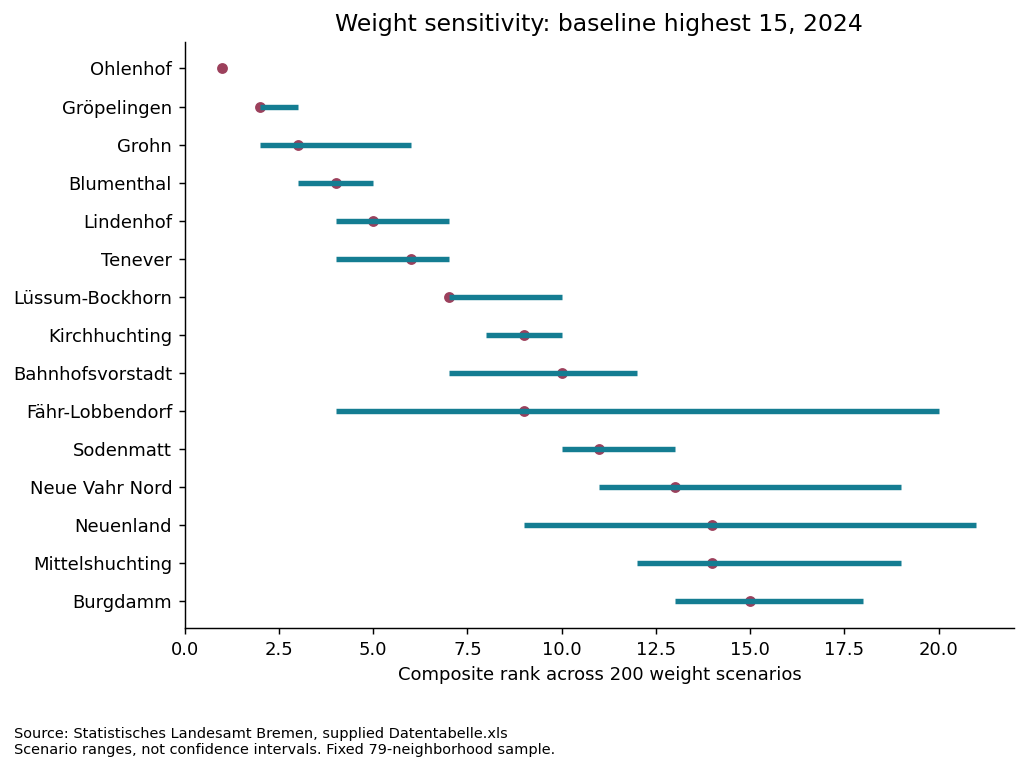

# Robustness evidence

Same 79 complete-case neighborhoods throughout; no resampling changes ranking coverage. Equal weights, domain-balanced weights (labour-market domain 0.5 split across two indicators; benefits 0.5), single-indicator emphasis, each indicator omitted, 200 constrained Dirichlet weight draws, and optional child-benefit inclusion are calculated for both ranking methods. Omission scenarios are diagnostics, not validated replacement indices. Random weights represent analyst choices, not probability distributions of true deprivation.

Composite/TOPSIS rank Spearman: 0.9743; Kendall tau-b: 0.8832. Lowest scenario rank correlation is 0.9622 (composite, plausible_random_135), with maximum rank movement 17. Full scenario results and top-ten overlap are in sensitivity_summary.csv. Rank ranges are NOT confidence intervals and do not quantify sampling error.

K-means initialization stability mean ARI 1.0000, minimum 1.0000. Bootstrap-neighborhood refitting mean ARI 0.8917, minimum 0.5913. Bootstrap models predict the full fixed standardized sample; this tests fitting-sample sensitivity, not longitudinal stability. Cluster labels are nominal.

Outliers flagged by 1.5-IQR fences remain in analysis; they are not automatically errors. Min-max index endpoints and TOPSIS vector normalization depend on the included sample. Correlated indicators, different denominators, absent income in 2024, unknown measurement error, and missing neighborhoods remain material uncertainties. Agreement between methods is not external validation. No method is objectively best on this evidence.


In [4]:
show_figure('weight_sensitivity.png')
display(Markdown((ROOT / 'results/robustness_findings.md').read_text(encoding='utf-8')))

## Assumptions and limits

Complete-case scoring; no imputation. Different indicator denominators, correlated labour-market measures, unavailable 2024 income, unknown exact reference dates and incomplete historical boundary/definition metadata limit interpretation. Rankings apply only to the covered sample. Clusters are nominal. See analysis/dataset_validation.md and docs/methods.md. Tables are exported by reusable scripts; important figures appear in results/figures/.